# Project 1:
## Customer Segmentation and Coupon Response | Python, SQL, scikit-learn, XGBoost
### Built a household feature table in SQL from 2.6M retail transactions (4-table join, pre-campaign data only) and segmented 2,495 customers into 4 groups with # KMeans; coupon redemption ranged from 35% to 9% across segments.

### Compared Logistic Regression, Random Forest and XGBoost with 5-fold cross-validation (best AUC 0.70); mailing the top 30% of households reaches 51% of redeemers, a 1.7x lift over random mailing.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [2]:
DATA_PATH = "/Users/aishighosh/Downloads/archive-5/"

trans = pd.read_csv(DATA_PATH + "transaction_data.csv")
product = pd.read_csv(DATA_PATH + "product.csv")
camp_desc = pd.read_csv(DATA_PATH + "campaign_desc.csv")
camp_table = pd.read_csv(DATA_PATH + "campaign_table.csv")
redempt = pd.read_csv(DATA_PATH + "coupon_redempt.csv")

print("Transactions:", trans.shape)
print("Households in transactions:", trans["household_key"].nunique())
print("Households targeted by at least one campaign:", camp_table["household_key"].nunique())
print("Households that redeemed at least one coupon:", redempt["household_key"].nunique())

Transactions: (2595732, 12)
Households in transactions: 2500
Households targeted by at least one campaign: 1584
Households that redeemed at least one coupon: 434


In [ ]:
#head shape


In [3]:
cutoff_day = camp_desc["START_DAY"].min()
print("First campaign starts on day", cutoff_day)

before = trans[trans["DAY"] < cutoff_day].copy()
print("Rows before the first campaign:", len(before))
print("Households with purchases before the first campaign:", before["household_key"].nunique())

First campaign starts on day 224
Rows before the first campaign: 627727
Households with purchases before the first campaign: 2496


In [4]:
#one row per household
before = before.merge(product[["PRODUCT_ID", "BRAND"]], on="PRODUCT_ID", how="left")

before["private_sales"] = 0.0
before.loc[before["BRAND"] == "Private", "private_sales"] = before["SALES_VALUE"]

hh = before.groupby("household_key").agg(
    monetary=("SALES_VALUE", "sum"),
    frequency=("BASKET_ID", "nunique"),
    last_day=("DAY", "max"),
    private_sales=("private_sales", "sum"),
    discount=("RETAIL_DISC", "sum"),
).reset_index()

hh = hh[hh["monetary"] > 0].copy()

hh["recency"] = cutoff_day - hh["last_day"]
hh["avg_basket"] = hh["monetary"] / hh["frequency"]
hh["private_share"] = hh["private_sales"] / hh["monetary"]
hh["discount_ratio"] = -hh["discount"] / hh["monetary"]

hh[["recency", "frequency", "monetary", "avg_basket", "private_share", "discount_ratio"]].describe().round(2)

,recency,frequency,monetary,avg_basket,private_share,discount_ratio
count,2495.00,2495.00,2495.00,2495.00,2495.00,2495.00
mean,23.30,28.03,763.15,31.01,0.27,0.19
std,38.65,32.40,847.95,22.54,0.15,0.10
min,1.00,1.00,1.00,1.00,0.00,-0.00
25%,2.00,9.00,201.86,15.99,0.16,0.13
50%,7.00,18.00,472.79,25.65,0.25,0.18
75%,22.00,35.00,994.30,39.28,0.35,0.24
max,223.00,351.00,7524.76,259.27,1.00,1.00


In [19]:
before.head(20)

,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC,BRAND,private_sales
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0,Private,1.39
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0,National,0.00
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0,Private,0.99
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0,National,0.00
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0,Private,1.50
5,2375,26984851516,1,826249,2,1.98,364,-0.60,1642,1,0.0,0.0,Private,1.98
6,2375,26984851516,1,1043142,1,1.57,364,-0.68,1642,1,0.0,0.0,National,0.00
7,2375,26984851516,1,1085983,1,2.99,364,-0.40,1642,1,0.0,0.0,National,0.00
8,2375,26984851516,1,1102651,1,1.89,364,0.00,1642,1,0.0,0.0,National,0.00
9,2375,26984851516,1,6423775,1,2.00,364,-0.79,1642,1,0.0,0.0,National,0.00


#prepare the clustering data
seg_data = hh[["recency", "frequency", "monetary", "avg_basket", "private_share"]].copy()

seg_data["recency"] = np.log1p(seg_data["recency"])
seg_data["frequency"] = np.log1p(seg_data["frequency"])
seg_data["monetary"] = np.log1p(seg_data["monetary"])
seg_data["avg_basket"] = np.log1p(seg_data["avg_basket"])

scaler = StandardScaler()
X_seg = scaler.fit_transform(seg_data)

print(X_seg.shape)

k = 2  inertia = 8328.3  silhouette = 0.321
k = 3  inertia = 7113.1  silhouette = 0.206
k = 4  inertia = 6226.2  silhouette = 0.197
k = 5  inertia = 5552.3  silhouette = 0.214
k = 6  inertia = 4922.6  silhouette = 0.21
k = 7  inertia = 4548.0  silhouette = 0.209
k = 8  inertia = 4267.3  silhouette = 0.196


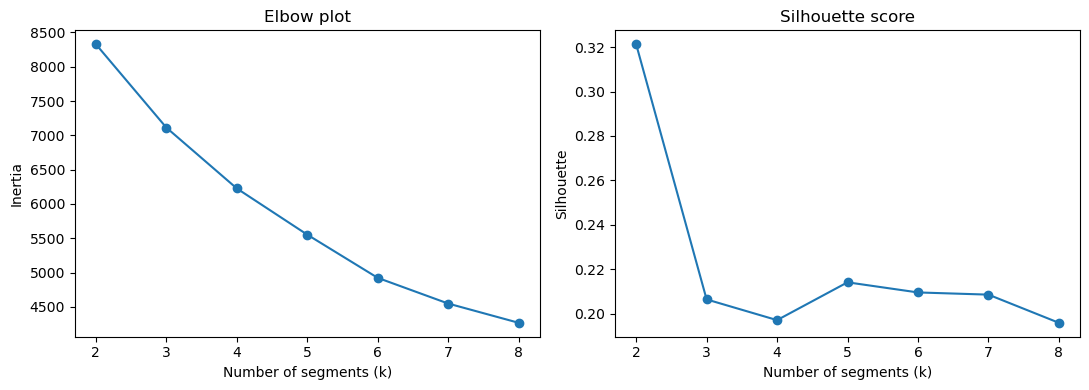

In [8]:
#choose the number of segments (elbow &silhoutte)
k_list = []
inertia_list = []
silhouette_list = []

for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_seg)
    k_list.append(k)
    inertia_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X_seg, labels))
    print("k =", k, " inertia =", round(km.inertia_, 1), " silhouette =", round(silhouette_list[-1], 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_list, inertia_list, marker="o")
axes[0].set_title("Elbow plot")
axes[0].set_xlabel("Number of segments (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_list, silhouette_list, marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of segments (k)")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

In [9]:
#fit k means with k=4
chosen_k = 4

kmeans = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
hh["cluster"] = kmeans.fit_predict(X_seg)

# Re-number the clusters so that Segment 1 is always the highest-spending group
avg_spend = hh.groupby("cluster")["monetary"].mean().sort_values(ascending=False)

rank_map = {}
rank = 1
for cluster_id in avg_spend.index:
    rank_map[cluster_id] = rank
    rank = rank + 1

hh["segment"] = hh["cluster"].map(rank_map)
hh["segment"].value_counts().sort_index()

segment
1    800
2    731
3    613
4    351
Name: count, dtype: int64

In [10]:
#segment profile 
profile = hh.groupby("segment")[["monetary", "frequency", "avg_basket", "recency", "private_share", "discount_ratio"]].mean().round(2)
profile["households"] = hh.groupby("segment")["household_key"].count()
profile

,monetary,frequency,avg_basket,recency,private_share,discount_ratio,households
segment,,,,,,,
1,1347.85,32.02,44.38,4.87,0.22,0.18,800
2,857.93,49.93,18.48,6.05,0.35,0.20,731
3,284.09,8.78,39.64,44.10,0.21,0.20,613
4,69.74,6.92,11.57,64.89,0.32,0.21,351


In [11]:
#target variable who redeemed a coupon 
targeted_ids = camp_table["household_key"].unique()
redeemed_ids = redempt["household_key"].unique()

hh["targeted"] = hh["household_key"].isin(targeted_ids)
hh["redeemed"] = hh["household_key"].isin(redeemed_ids).astype(int)

model_df = hh[hh["targeted"]].copy()

print("Targeted households used for modelling:", len(model_df))
print("Redeemers:", model_df["redeemed"].sum())
print("Overall redemption rate:", round(model_df["redeemed"].mean() * 100, 1), "%")

Targeted households used for modelling: 1583
Redeemers: 433
Overall redemption rate: 27.4 %


         targeted_households  redeemers  redemption_rate
segment                                                 
1                        711        247             34.7
2                        610        152             24.9
3                        208         29             13.9
4                         54          5              9.3


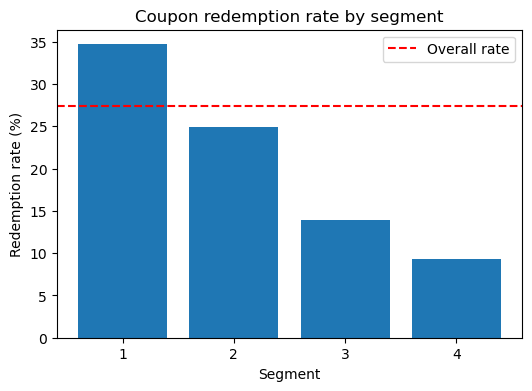

In [12]:
#redemption rate by segment 
rate_by_segment = model_df.groupby("segment")["redeemed"].agg(["count", "sum", "mean"])
rate_by_segment.columns = ["targeted_households", "redeemers", "redemption_rate"]
rate_by_segment["redemption_rate"] = (rate_by_segment["redemption_rate"] * 100).round(1)
print(rate_by_segment)

plt.figure(figsize=(6, 4))
plt.bar(rate_by_segment.index.astype(str), rate_by_segment["redemption_rate"])
plt.axhline(model_df["redeemed"].mean() * 100, color="red", linestyle="--", label="Overall rate")
plt.xlabel("Segment")
plt.ylabel("Redemption rate (%)")
plt.title("Coupon redemption rate by segment")
plt.legend()
plt.show()

In [13]:
#compare the 3 models
feature_list = ["recency", "frequency", "monetary", "avg_basket", "private_share", "discount_ratio"]

X = model_df[feature_list]
y = model_df["redeemed"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Model 1: Logistic Regression (baseline), scaling is part of the pipeline
log_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# Model 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42)

# Model 3: XGBoost
xgb_model = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, eval_metric="logloss", random_state=42)

log_scores = cross_val_score(log_model, X, y, cv=cv, scoring="roc_auc")
rf_scores = cross_val_score(rf_model, X, y, cv=cv, scoring="roc_auc")
xgb_scores = cross_val_score(xgb_model, X, y, cv=cv, scoring="roc_auc")

print("Logistic Regression AUC:", round(log_scores.mean(), 3), "+/-", round(log_scores.std(), 3))
print("Random Forest AUC:      ", round(rf_scores.mean(), 3), "+/-", round(rf_scores.std(), 3))
print("XGBoost AUC:            ", round(xgb_scores.mean(), 3), "+/-", round(xgb_scores.std(), 3))

Logistic Regression AUC: 0.702 +/- 0.046
Random Forest AUC:       0.666 +/- 0.038
XGBoost AUC:             0.675 +/- 0.036


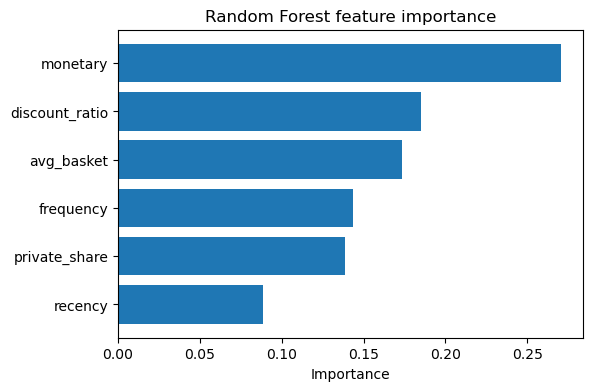

In [14]:
#feature importance
rf_model.fit(X, y)
importance = pd.Series(rf_model.feature_importances_, index=feature_list).sort_values()

plt.figure(figsize=(6, 4))
plt.barh(importance.index, importance.values)
plt.xlabel("Importance")
plt.title("Random Forest feature importance")
plt.show()

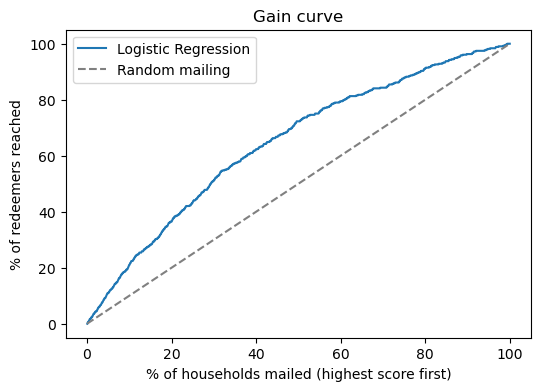

Best model by AUC: Logistic Regression (AUC 0.702 )
Mail the top 30 % of households ( 474 of 1583 )
This reaches 221 of 433 redeemers = 51.0 %
Lift over random mailing: 1.7 x


In [15]:
#targetting rule and gain curve 
best_name = "Logistic Regression"
best_model = log_model
best_auc = log_scores.mean()

if rf_scores.mean() > best_auc:
    best_name = "Random Forest"
    best_model = rf_model
    best_auc = rf_scores.mean()

if xgb_scores.mean() > best_auc:
    best_name = "XGBoost"
    best_model = xgb_model
    best_auc = xgb_scores.mean()

best_prob = cross_val_predict(best_model, X, y, cv=cv, method="predict_proba")[:, 1]

lift_df = pd.DataFrame({"actual": y.values, "score": best_prob})
lift_df = lift_df.sort_values("score", ascending=False).reset_index(drop=True)

top_share = 0.30
top_n = int(len(lift_df) * top_share)

redeemers_in_top = lift_df.loc[:top_n - 1, "actual"].sum()
redeemers_total = lift_df["actual"].sum()
capture_rate = redeemers_in_top / redeemers_total

lift_df["cum_redeemers_pct"] = lift_df["actual"].cumsum() / redeemers_total * 100
lift_df["mailed_pct"] = (lift_df.index + 1) / len(lift_df) * 100

plt.figure(figsize=(6, 4))
plt.plot(lift_df["mailed_pct"], lift_df["cum_redeemers_pct"], label=best_name)
plt.plot([0, 100], [0, 100], color="grey", linestyle="--", label="Random mailing")
plt.xlabel("% of households mailed (highest score first)")
plt.ylabel("% of redeemers reached")
plt.title("Gain curve")
plt.legend()
plt.show()

print("Best model by AUC:", best_name, "(AUC", round(best_auc, 3), ")")
print("Mail the top", int(top_share * 100), "% of households (", top_n, "of", len(lift_df), ")")
print("This reaches", redeemers_in_top, "of", redeemers_total, "redeemers =", round(capture_rate * 100, 1), "%")
print("Lift over random mailing:", round(capture_rate / top_share, 2), "x")

# Project 2:
## Price Elasticity and Discount Break-Even Analysis | Python, SQL, statsmodels
### Estimated price elasticity for 12 grocery categories (-1.2 to -3.4) from 2 years of weekly data using a fixed-effects regression with display and mailer promotion controls.

### With no cost data, derived the margin each category needs for a 5% discount to pay off (31% to 83%); only fluid milk and soft drinks come near typical grocery margins, so discounts elsewhere should be held.


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

In [21]:
#load files
DATA_PATH = "/Users/aishighosh/Downloads/archive-5/"

trans = pd.read_csv(DATA_PATH + "transaction_data.csv")
product = pd.read_csv(DATA_PATH + "product.csv")
promo = pd.read_csv(DATA_PATH + "causal_small.csv.gz")

print("Transactions:", trans.shape)
print("Products:", product.shape)
print("Promotion rows (product-week):", promo.shape)

Transactions: (2595732, 12)
Products: (92353, 7)
Promotion rows (product-week): (2049187, 4)


In [22]:
# Attach the category (commodity) and department to every transaction line
data = trans.merge(product[["PRODUCT_ID", "COMMODITY_DESC", "DEPARTMENT"]], on="PRODUCT_ID", how="left")

# Pick the 12 biggest GROCERY categories by sales
grocery = data[data["DEPARTMENT"] == "GROCERY"]
category_sales = grocery.groupby("COMMODITY_DESC")["SALES_VALUE"].sum()
category_sales = category_sales.sort_values(ascending=False)
top_categories = category_sales.head(12).index

print(list(top_categories))

['SOFT DRINKS', 'FLUID MILK PRODUCTS', 'CHEESE', 'FRZN MEAT/MEAT DINNERS', 'BAG SNACKS', 'BEERS/ALES', 'FROZEN PIZZA', 'BAKED BREAD/BUNS/ROLLS', 'COLD CEREAL', 'SOUP', 'ICE CREAM/MILK/SHERBTS', 'CANNED JUICES']


In [23]:
# Keep only valid lines of the top categories
valid = data[data["COMMODITY_DESC"].isin(top_categories)]
valid = valid[(valid["QUANTITY"] > 0) & (valid["SALES_VALUE"] > 0)]

# Total sales and number of weeks sold for each product
product_totals = valid.groupby(["COMMODITY_DESC", "PRODUCT_ID"]).agg(
    sales=("SALES_VALUE", "sum"),
    weeks_sold=("WEEK_NO", "nunique"),
).reset_index()

# Keep products that sold in at least 60 weeks
product_totals = product_totals[product_totals["weeks_sold"] >= 60]

# Keep the 10 best-selling products in each category
product_totals = product_totals.sort_values(["COMMODITY_DESC", "sales"], ascending=[True, False])
product_totals["sales_rank"] = product_totals.groupby("COMMODITY_DESC").cumcount() + 1
chosen_products = product_totals[product_totals["sales_rank"] <= 10]

print("Chosen products:", len(chosen_products))

Chosen products: 120


In [24]:
# Weekly units and average price for each chosen product
valid = valid.merge(chosen_products[["PRODUCT_ID"]], on="PRODUCT_ID", how="inner")

panel = valid.groupby(["COMMODITY_DESC", "PRODUCT_ID", "WEEK_NO"]).agg(
    units=("QUANTITY", "sum"),
    sales=("SALES_VALUE", "sum"),
).reset_index()

panel["price"] = panel["sales"] / panel["units"]
panel = panel.rename(columns={"COMMODITY_DESC": "commodity"})

# Add the promotion flags (a week with no record means no display / mailer)
panel = panel.merge(promo, on=["PRODUCT_ID", "WEEK_NO"], how="left")
panel["display_share"] = panel["display_share"].fillna(0)
panel["mailer_share"] = panel["mailer_share"].fillna(0)

print("Product-week rows:", panel.shape[0])
panel.groupby("commodity").agg(
    products=("PRODUCT_ID", "nunique"),
    product_weeks=("units", "size"),
    avg_units_per_week=("units", "mean"),
    avg_price=("price", "mean"),
).round(2)

Product-week rows: 11384


,products,product_weeks,avg_units_per_week,avg_price
commodity,,,,
BAG SNACKS,10,926,13.25,2.81
BAKED BREAD/BUNS/ROLLS,10,1016,45.29,1.39
BEERS/ALES,10,912,4.04,11.49
CANNED JUICES,10,887,7.49,2.10
CHEESE,10,1009,28.11,2.01
COLD CEREAL,10,927,5.40,3.33
FLUID MILK PRODUCTS,10,1017,93.86,1.97
FROZEN PIZZA,10,956,10.44,3.14
FRZN MEAT/MEAT DINNERS,10,893,8.00,4.33


In [25]:
panel["log_units"] = np.log(panel["units"])
panel["log_price"] = np.log(panel["price"])

panel[["units", "price", "log_units", "log_price", "display_share", "mailer_share"]].describe().round(2)

,units,price,log_units,log_price,display_share,mailer_share
count,11384.00,11384.00,11384.00,11384.00,11384.00,11384.00
mean,23.94,3.31,2.28,0.91,0.71,0.17
std,44.77,3.12,1.32,0.71,0.42,0.38
min,1.00,0.49,0.00,-0.70,0.00,0.00
25%,4.00,1.55,1.39,0.44,0.29,0.00
50%,9.00,2.31,2.20,0.84,1.00,0.00
75%,25.00,3.77,3.22,1.33,1.00,0.00
max,604.00,17.99,6.40,2.89,1.00,1.00


In [26]:
# one regression per category to get the price elatsicity 
result_rows = []

for commodity_name in sorted(panel["commodity"].unique()):
    one = panel[panel["commodity"] == commodity_name]

    model = smf.ols(
        "log_units ~ log_price + display_share + mailer_share + C(PRODUCT_ID) + C(WEEK_NO)",
        data=one,
    ).fit(cov_type="HC1")

    elasticity = model.params["log_price"]
    std_error = model.bse["log_price"]

    result_rows.append([commodity_name, len(one), elasticity, std_error])

result = pd.DataFrame(result_rows, columns=["commodity", "product_weeks", "elasticity", "std_error"])
result["ci_low"] = result["elasticity"] - 1.96 * result["std_error"]
result["ci_high"] = result["elasticity"] + 1.96 * result["std_error"]

result.sort_values("elasticity").round(2)

,commodity,product_weeks,elasticity,std_error,ci_low,ci_high
6,FLUID MILK PRODUCTS,1017,-3.43,0.13,-3.69,-3.18
10,SOFT DRINKS,1009,-3.17,0.15,-3.46,-2.87
7,FROZEN PIZZA,956,-2.47,0.17,-2.81,-2.13
5,COLD CEREAL,927,-2.47,0.22,-2.91,-2.03
4,CHEESE,1009,-2.32,0.13,-2.57,-2.07
3,CANNED JUICES,887,-2.15,0.17,-2.47,-1.82
11,SOUP,937,-1.70,0.19,-2.07,-1.34
9,ICE CREAM/MILK/SHERBTS,895,-1.67,0.17,-1.99,-1.34
2,BEERS/ALES,912,-1.53,0.68,-2.87,-0.19
8,FRZN MEAT/MEAT DINNERS,893,-1.53,0.25,-2.03,-1.04


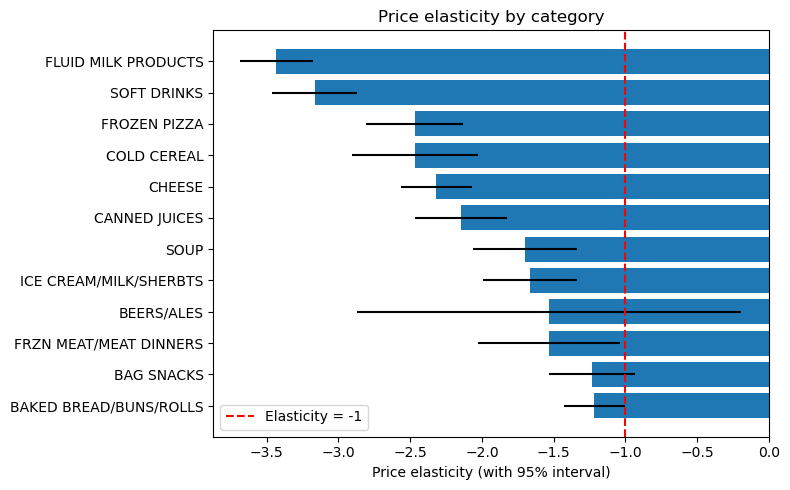

In [27]:
# elasticity Chart
plot_df = result.sort_values("elasticity", ascending=False)

plt.figure(figsize=(8, 5))
plt.barh(plot_df["commodity"], plot_df["elasticity"], xerr=1.96 * plot_df["std_error"])
plt.axvline(-1, color="red", linestyle="--", label="Elasticity = -1")
plt.xlabel("Price elasticity (with 95% interval)")
plt.title("Price elasticity by category")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
# What happens to units and revenue if the price is cut by 5%? (no cost data needed)
result["units_change_pct"] = ((0.95 ** result["elasticity"]) - 1) * 100
result["revenue_change_pct"] = ((0.95 ** (1 + result["elasticity"])) - 1) * 100

# Break-even margin for a 5% price cut.
# k = how many times more units we sell after the cut = 0.95 ** elasticity
# The cut raises profit only if gross margin (in %) is above 5 * k / (k - 1)
break_even_list = []
be_low_list = []
be_high_list = []

for i in range(len(result)):
    b_point = result["elasticity"].iloc[i]
    b_low = result["ci_low"].iloc[i]
    b_high = result["ci_high"].iloc[i]

    if b_point < 0:
        k_point = 0.95 ** b_point
        break_even_list.append(5 * k_point / (k_point - 1))
    else:
        break_even_list.append(np.nan)

    if b_low < 0:
        k_low = 0.95 ** b_low
        be_low_list.append(5 * k_low / (k_low - 1))
    else:
        be_low_list.append(np.nan)

    if b_high < 0:
        k_high = 0.95 ** b_high
        be_high_list.append(5 * k_high / (k_high - 1))
    else:
        be_high_list.append(np.nan)

result["break_even_margin_pct"] = break_even_list
result["break_even_low_pct"] = be_low_list
result["break_even_high_pct"] = be_high_list

result[["commodity", "elasticity", "units_change_pct", "revenue_change_pct", "break_even_margin_pct", "break_even_low_pct", "break_even_high_pct"]].sort_values("break_even_margin_pct").round(1)

,commodity,elasticity,units_change_pct,revenue_change_pct,break_even_margin_pct,break_even_low_pct,break_even_high_pct
6,FLUID MILK PRODUCTS,-3.4,19.3,13.3,31.0,29.0,33.2
10,SOFT DRINKS,-3.2,17.6,11.7,33.4,30.7,36.5
7,FROZEN PIZZA,-2.5,13.5,7.8,42.0,37.3,48.3
5,COLD CEREAL,-2.5,13.5,7.8,42.1,36.1,50.6
4,CHEESE,-2.3,12.6,7.0,44.6,40.5,49.6
3,CANNED JUICES,-2.1,11.6,6.1,48.0,42.0,56.0
11,SOUP,-1.7,9.1,3.7,59.8,49.7,75.3
9,ICE CREAM/MILK/SHERBTS,-1.7,8.9,3.5,61.1,51.5,75.4
2,BEERS/ALES,-1.5,8.2,2.8,66.1,36.5,504.5
8,FRZN MEAT/MEAT DINNERS,-1.5,8.2,2.8,66.2,50.7,96.4


In [30]:
# decision table with 20/30/40% ,margins assumed
# ASSUMED gross margins for grocery (not in the data): 20%, 30%, 40%
# A discount pays at a given margin only if that margin is ABOVE the category's break-even margin

result["pays_at_20pct"] = result["break_even_margin_pct"] < 20
result["pays_at_30pct"] = result["break_even_margin_pct"] < 30
result["pays_at_40pct"] = result["break_even_margin_pct"] < 40

decision_list = []

for i in range(len(result)):
    break_even = result["break_even_margin_pct"].iloc[i]

    if break_even <= 30:
        decision_list.append("Discount may pay")
    elif break_even <= 40:
        decision_list.append("Test first")
    else:
        decision_list.append("Hold price")

result["decision"] = decision_list

result[["commodity", "elasticity", "break_even_margin_pct", "pays_at_20pct", "pays_at_30pct", "pays_at_40pct", "decision"]].sort_values("break_even_margin_pct").round(1)

,commodity,elasticity,break_even_margin_pct,pays_at_20pct,pays_at_30pct,pays_at_40pct,decision
6,FLUID MILK PRODUCTS,-3.4,31.0,False,False,True,Test first
10,SOFT DRINKS,-3.2,33.4,False,False,True,Test first
7,FROZEN PIZZA,-2.5,42.0,False,False,False,Hold price
5,COLD CEREAL,-2.5,42.1,False,False,False,Hold price
4,CHEESE,-2.3,44.6,False,False,False,Hold price
3,CANNED JUICES,-2.1,48.0,False,False,False,Hold price
11,SOUP,-1.7,59.8,False,False,False,Hold price
9,ICE CREAM/MILK/SHERBTS,-1.7,61.1,False,False,False,Hold price
2,BEERS/ALES,-1.5,66.1,False,False,False,Hold price
8,FRZN MEAT/MEAT DINNERS,-1.5,66.2,False,False,False,Hold price


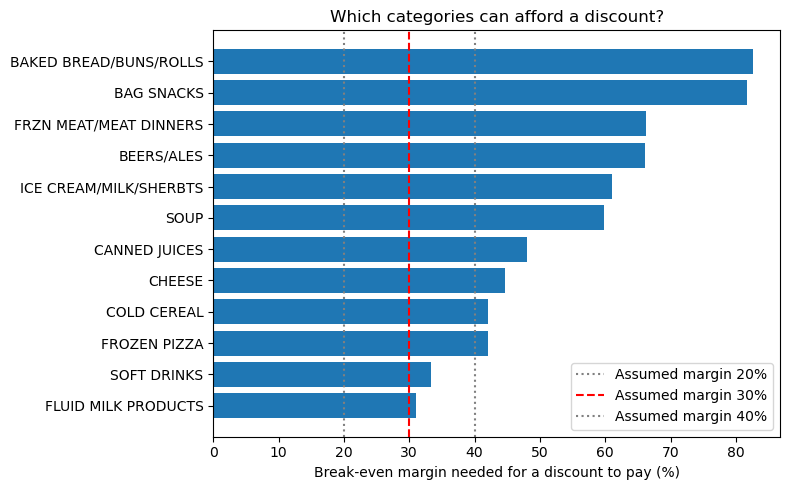

In [32]:
# break even Chart
chart_df = result.sort_values("break_even_margin_pct")

plt.figure(figsize=(8, 5))
plt.barh(chart_df["commodity"], chart_df["break_even_margin_pct"])
plt.axvline(20, color="grey", linestyle=":", label="Assumed margin 20%")
plt.axvline(30, color="red", linestyle="--", label="Assumed margin 30%")
plt.axvline(40, color="grey", linestyle=":", label="Assumed margin 40%")
plt.xlabel("Break-even margin needed for a discount to pay (%)")
plt.title("Which categories can afford a discount?")
plt.legend()
plt.tight_layout()
plt.show()